# Lifestyle & Biometric Age Inference: Predicting Age via Health & Behavioral Patterns
**Healthcare Analytics & Predictive Modeling**

This notebook demonstrates a Machine Learning pipeline to infer customer age from lifestyle behaviors, biometric measurements (height, weight), eating patterns, physical activity levels, and family health history in the Obesity Dataset (2,111 records).

**Pipeline Overview:**
- Exploratory Data Analysis & Feature Correlation
- Binary Encoding of Health Behaviors & Categorical One-Hot Encoding
- Feature Scaling with StandardScaler
- Comparative Evaluation: Linear Regression vs. Decision Tree vs. Multi-Layer Perceptron
- Epoch-wise Training Loss Monitoring & Learning Curve Analysis


In [67]:
# Data ingestion with fallback paths
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

DATA_PATHS = [
    '../data/sample_obesity_lifestyle.csv',
    '../Updated_Obesity_Dataset.csv',
    'Updated_Obesity_Dataset.csv',
    '/sessions/practical-ecstatic-darwin/mnt/Github/Brac_Projects/CSE422/Updated_Obesity_Dataset.csv'
]

dataset = None
for p in DATA_PATHS:
    if os.path.exists(p):
        dataset = pd.read_csv(p)
        print(f'Successfully loaded dataset from: {p} (shape: {dataset.shape})')
        break

if dataset is None:
    raise FileNotFoundError('Obesity Dataset not found in expected locations.')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


,Age,Gender,Height,Weight,CALC,FAVC,FCVC,NCP,SCC,SMOKE,CH2O,family_history_with_overweight,FAF,TUE,CAEC,MTRANS,NObeyesdad
0,21.000000,Female,1.620000,64.000000,no,no,2.0,3.0,no,no,2.000000,yes,0.000000,1.000000,Sometimes,Public_Transportation,Normal_Weight
1,21.000000,Female,1.520000,56.000000,Sometimes,no,3.0,3.0,yes,yes,3.000000,yes,3.000000,0.000000,Sometimes,Public_Transportation,Normal_Weight
2,23.000000,Male,1.800000,77.000000,Frequently,no,2.0,3.0,no,no,2.000000,yes,2.000000,1.000000,Sometimes,Public_Transportation,Normal_Weight
3,27.000000,Male,1.800000,87.000000,Frequently,no,3.0,3.0,no,no,2.000000,no,2.000000,0.000000,Sometimes,Walking,Overweight_Level_I
4,22.000000,Male,1.780000,89.800000,Sometimes,no,2.0,1.0,no,no,2.000000,no,0.000000,0.000000,Sometimes,Public_Transportation,Overweight_Level_II
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2106,20.976842,Female,1.710730,131.408528,Sometimes,yes,3.0,3.0,no,no,1.728139,yes,1.676269,0.906247,Sometimes,Public_Transportation,Obesity_Type_III
2107,21.982942,Female,1.748584,133.742943,Sometimes,yes,3.0,3.0,no,no,2.005130,yes,1.341390,0.599270,Sometimes,Public_Transportation,Obesity_Type_III
2108,22.524036,Female,1.752206,133.689352,Sometimes,yes,3.0,3.0,no,no,2.054193,yes,1.414209,0.646288,Sometimes,Public_Transportation,Obesity_Type_III
2109,24.361936,Female,1.739450,133.346641,Sometimes,yes,3.0,3.0,no,no,2.852339,yes,1.139107,0.586035,Sometimes,Public_Transportation,Obesity_Type_III


Features

In [68]:
dataset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2111 entries, 0 to 2110
Data columns (total 17 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Age                             2111 non-null   float64
 1   Gender                          2100 non-null   object 
 2   Height                          2111 non-null   float64
 3   Weight                          2111 non-null   float64
 4   CALC                            2111 non-null   object 
 5   FAVC                            2111 non-null   object 
 6   FCVC                            2111 non-null   float64
 7   NCP                             2111 non-null   float64
 8   SCC                             2111 non-null   object 
 9   SMOKE                           2111 non-null   object 
 10  CH2O                            2090 non-null   float64
 11  family_history_with_overweight  2090 non-null   object 
 12  FAF                             21

Numerical Features

In [69]:
##Selecting numerical features
numerical_data = dataset.select_dtypes(include='number')

#append the features of numerical_data to list
numerical_features=numerical_data.columns.tolist()

print(f'There are {len(numerical_features)} numerical features:', '\n')
print(numerical_features)

There are 8 numerical features: 

['Age', 'Height', 'Weight', 'FCVC', 'NCP', 'CH2O', 'FAF', 'TUE']


Categorical Features

In [70]:
#Selecting categoricalfeatures
categorical_data=dataset.select_dtypes(include= 'object')

#append the features of categorical_data to list
categorical_features=categorical_data.columns.tolist()

print(f'There are {len(categorical_features)} categorical features:', '\n')
print(categorical_features)

There are 9 categorical features: 

['Gender', 'CALC', 'FAVC', 'SCC', 'SMOKE', 'family_history_with_overweight', 'CAEC', 'MTRANS', 'NObeyesdad']


Data points

In [71]:
print ('Shape of the dataset is {}. This dataset contains {} rows and {} columns.'.format(dataset.shape,dataset.shape[0],dataset.shape[1]))

Shape of the dataset is (2111, 17). This dataset contains 2111 rows and 17 columns.


Correlation Analysis

In [72]:
#Correlation matrix of whole dataset
correlation_matrix = numerical_data.corr()
correlation_matrix


,Age,Height,Weight,FCVC,NCP,CH2O,FAF,TUE
Age,1.000000,-0.025958,0.202560,0.016291,-0.043944,-0.044532,-0.144938,-0.296931
Height,-0.025958,1.000000,0.463136,-0.038121,0.243672,0.214998,0.294709,0.051912
Weight,0.202560,0.463136,1.000000,0.216125,0.107469,0.198787,-0.051436,-0.071561
FCVC,0.016291,-0.038121,0.216125,1.000000,0.042216,0.068626,0.019939,-0.101135
NCP,-0.043944,0.243672,0.107469,0.042216,1.000000,0.058266,0.129504,0.036326
CH2O,-0.044532,0.214998,0.198787,0.068626,0.058266,1.000000,0.170020,0.009781
FAF,-0.144938,0.294709,-0.051436,0.019939,0.129504,0.170020,1.000000,0.058562
TUE,-0.296931,0.051912,-0.071561,-0.101135,0.036326,0.009781,0.058562,1.000000


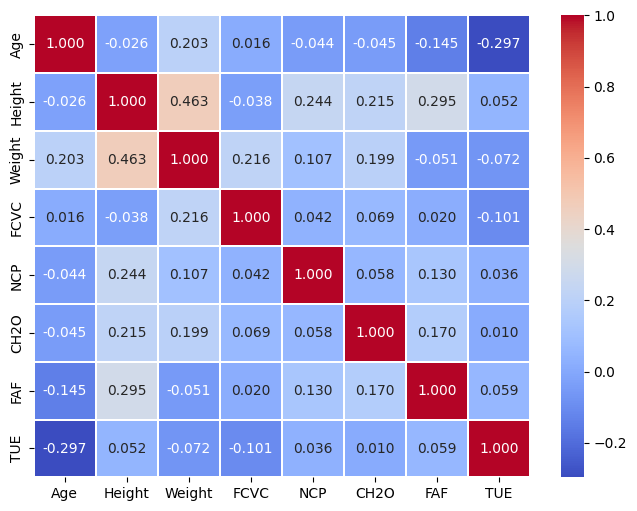

In [73]:
# Plotting the heatmap for correlation matrix
plt.figure(figsize=(8, 6))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.3f', linewidths=0.3)
plt.show()

Encoding of categorical features and correlation analysis of all features

In [74]:
from sklearn.preprocessing import LabelEncoder
dataset_encoded = dataset.copy()
encoder = LabelEncoder()

for col in dataset_encoded.select_dtypes(include=['object']).columns:
    dataset_encoded[col] = encoder.fit_transform(dataset_encoded[col])

# Correlation matrix
corr = dataset_encoded.corr()
corr

,Age,Gender,Height,Weight,CALC,FAVC,FCVC,NCP,SCC,SMOKE,CH2O,family_history_with_overweight,FAF,TUE,CAEC,MTRANS,NObeyesdad
Age,1.000000,0.047269,-0.025958,0.202560,-0.044487,0.063902,0.016291,-0.043944,-0.116283,0.091987,-0.044532,0.196848,-0.144938,-0.296931,0.083739,-0.601945,0.236170
Gender,0.047269,1.000000,0.590605,0.150330,0.009080,0.064239,-0.269776,0.050285,-0.095532,0.041236,0.101777,0.096629,0.176623,0.008694,0.085112,-0.131079,0.020941
Height,-0.025958,0.590605,1.000000,0.463136,-0.129732,0.178364,-0.038121,0.243672,-0.133753,0.055499,0.214998,0.237736,0.294709,0.051912,0.048818,-0.073609,0.038986
Weight,0.202560,0.150330,0.463136,1.000000,-0.206677,0.272300,0.216125,0.107469,-0.201906,0.025746,0.198787,0.476907,-0.051436,-0.071561,0.287493,0.004610,0.387643
CALC,-0.044487,0.009080,-0.129732,-0.206677,1.000000,-0.089520,-0.060781,-0.071747,-0.003463,-0.082471,-0.092249,0.037646,0.086799,0.045864,-0.047540,-0.012452,-0.134632
FAVC,0.063902,0.064239,0.178364,0.272300,-0.089520,1.000000,-0.027283,-0.007000,-0.190658,-0.050660,0.008390,0.205120,-0.107995,0.068417,0.150068,-0.069800,0.044582
FCVC,0.016291,-0.269776,-0.038121,0.216125,-0.060781,-0.027283,1.000000,0.042216,0.071852,0.014320,0.068626,0.039342,0.019939,-0.101135,-0.054670,0.064743,0.018522
NCP,-0.043944,0.050285,0.243672,0.107469,-0.071747,-0.007000,0.042216,1.000000,-0.015624,0.007811,0.058266,0.068463,0.129504,0.036326,-0.097801,-0.053858,-0.092616
SCC,-0.116283,-0.095532,-0.133753,-0.201906,-0.003463,-0.190658,0.071852,-0.015624,1.000000,0.047731,0.004035,-0.177743,0.074221,-0.010928,-0.109179,0.043157,-0.050679
SMOKE,0.091987,0.041236,0.055499,0.025746,-0.082471,-0.050660,0.014320,0.007811,0.047731,1.000000,-0.032709,0.012891,0.011216,0.017613,-0.055282,-0.010702,-0.023256


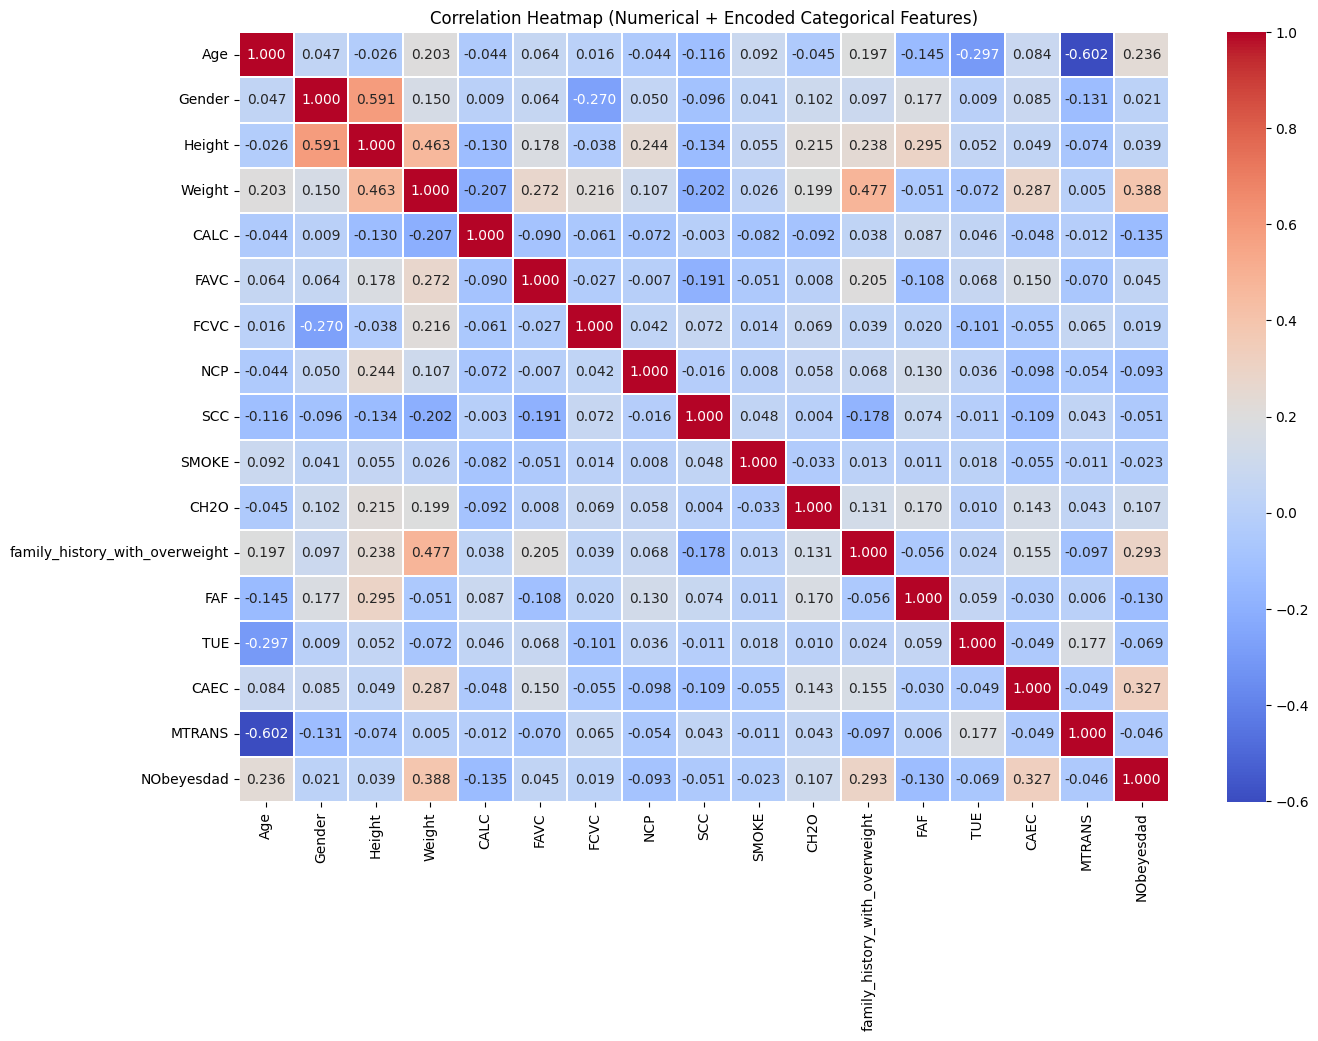

In [75]:
plt.figure(figsize=(15,10))
sns.heatmap(corr, cmap="coolwarm", annot=True, fmt='.3f', linewidths=0.3)
plt.title("Correlation Heatmap (Numerical + Encoded Categorical Features)")
plt.show()

Correlation plot between features and target

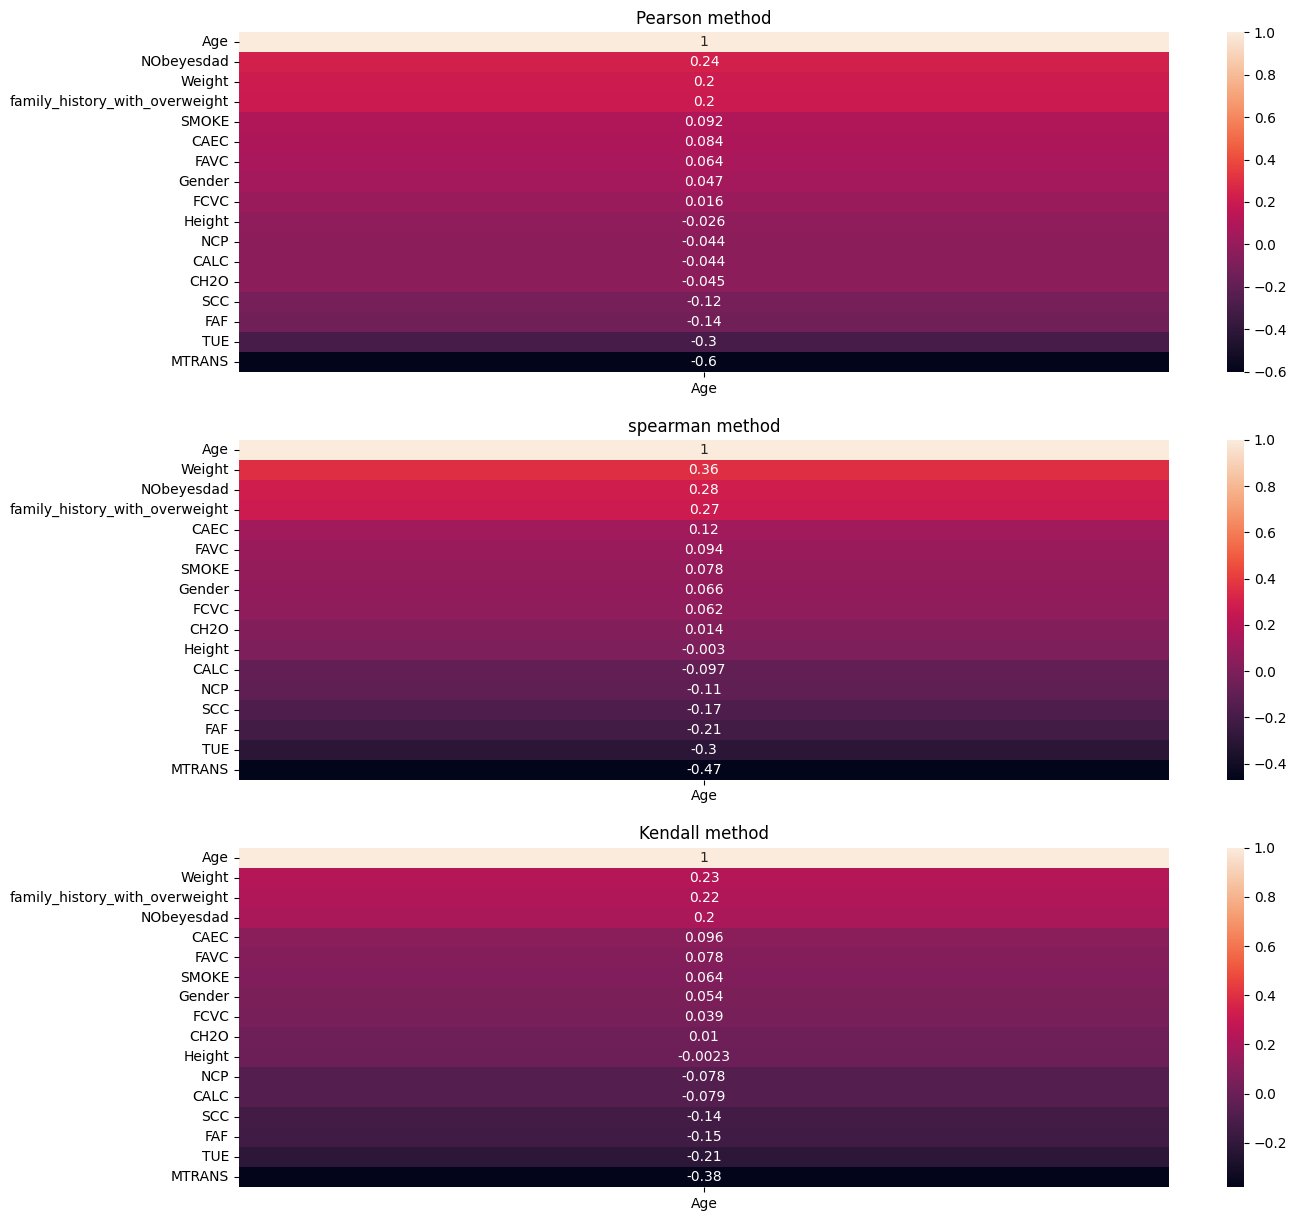

In [76]:
fig, ax = plt.subplots(3,1, figsize=(15, 15))
## Correlation coefficient using different methods
corr1 = dataset_encoded.corr('pearson')[['Age']].sort_values(by='Age', ascending=False)
corr2 = dataset_encoded.corr('spearman')[['Age']].sort_values(by='Age', ascending=False)
corr3 = dataset_encoded.corr('kendall')[['Age']].sort_values(by='Age', ascending=False)

#setting titles for each plot
ax[0].set_title('Pearson method')
ax[1].set_title('spearman method')
ax[2].set_title('Kendall method')

## Generating heatmaps of each methods
sns.heatmap(corr1, ax=ax[0], annot=True)
sns.heatmap(corr2, ax=ax[1], annot=True)
sns.heatmap(corr3, ax=ax[2], annot=True)

plt.show()

No of unique values in each feature

In [77]:
unique_counts=dataset_encoded.nunique()
print(unique_counts)

Age                               1402
Gender                               3
Height                            1574
Weight                            1525
CALC                                 4
FAVC                                 2
FCVC                               810
NCP                                635
SCC                                  2
SMOKE                                2
CH2O                              1260
family_history_with_overweight       3
FAF                               1190
TUE                               1129
CAEC                                 4
MTRANS                               5
NObeyesdad                           7
dtype: int64


Barplot of unique value counts in age

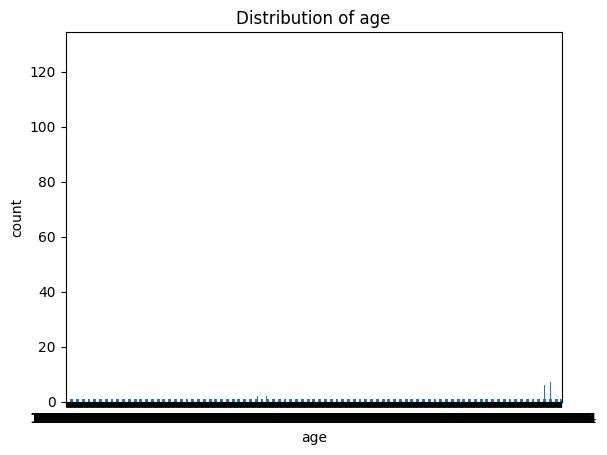

In [78]:
plt.title(f'Distribution of age')
numerical_data['Age'].value_counts().sort_index().plot(kind='bar', rot=0, xlabel="age",ylabel='count')
plt.show()

Summary satistics of Numerical Features

In [79]:
numerical_data.describe().T

,count,mean,std,min,25%,50%,75%,max
Age,2111.0,24.312600,6.345968,14.00,19.947192,22.777890,26.000000,61.00
Height,2111.0,1.701677,0.093305,1.45,1.630000,1.700499,1.768464,1.98
Weight,2111.0,86.586058,26.191172,39.00,65.473343,83.000000,107.430682,173.00
FCVC,2111.0,2.419043,0.533927,1.00,2.000000,2.385502,3.000000,3.00
NCP,2111.0,2.685628,0.778039,1.00,2.658738,3.000000,3.000000,4.00
CH2O,2090.0,2.009034,0.613164,1.00,1.582010,2.000000,2.479917,3.00
FAF,2111.0,1.010298,0.850592,0.00,0.124505,1.000000,1.666678,3.00
TUE,2111.0,0.657866,0.608927,0.00,0.000000,0.625350,1.000000,2.00


Summary satistics of Categorical features

In [80]:
categorical_data.describe().T

,count,unique,top,freq
Gender,2100,2,Male,1065
CALC,2111,4,Sometimes,1401
FAVC,2111,2,yes,1866
SCC,2111,2,no,2015
SMOKE,2111,2,no,2067
family_history_with_overweight,2090,2,yes,1706
CAEC,2111,4,Sometimes,1765
MTRANS,2111,5,Public_Transportation,1580
NObeyesdad,2111,7,Obesity_Type_I,351


Skew in features

In [81]:
dataset_encoded.skew()

,0
Age,1.529100
Gender,0.058143
Height,-0.012855
Weight,0.255410
CALC,0.236481
FAVC,-2.399125
FCVC,-0.432906
NCP,-1.107097
SCC,4.366270
SMOKE,6.712867


Histograms and Box Plot

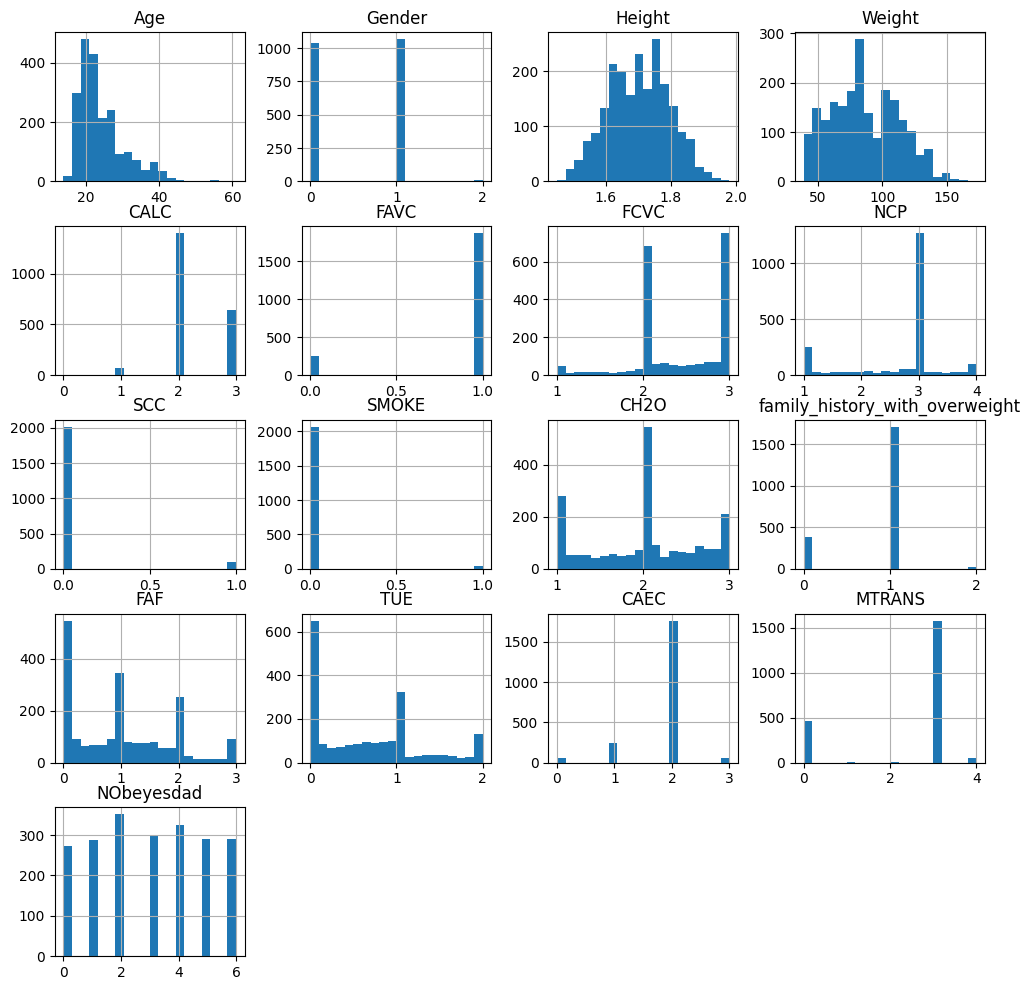

In [82]:
dataset_encoded.hist(figsize=(12,12),bins=20)
plt.show()

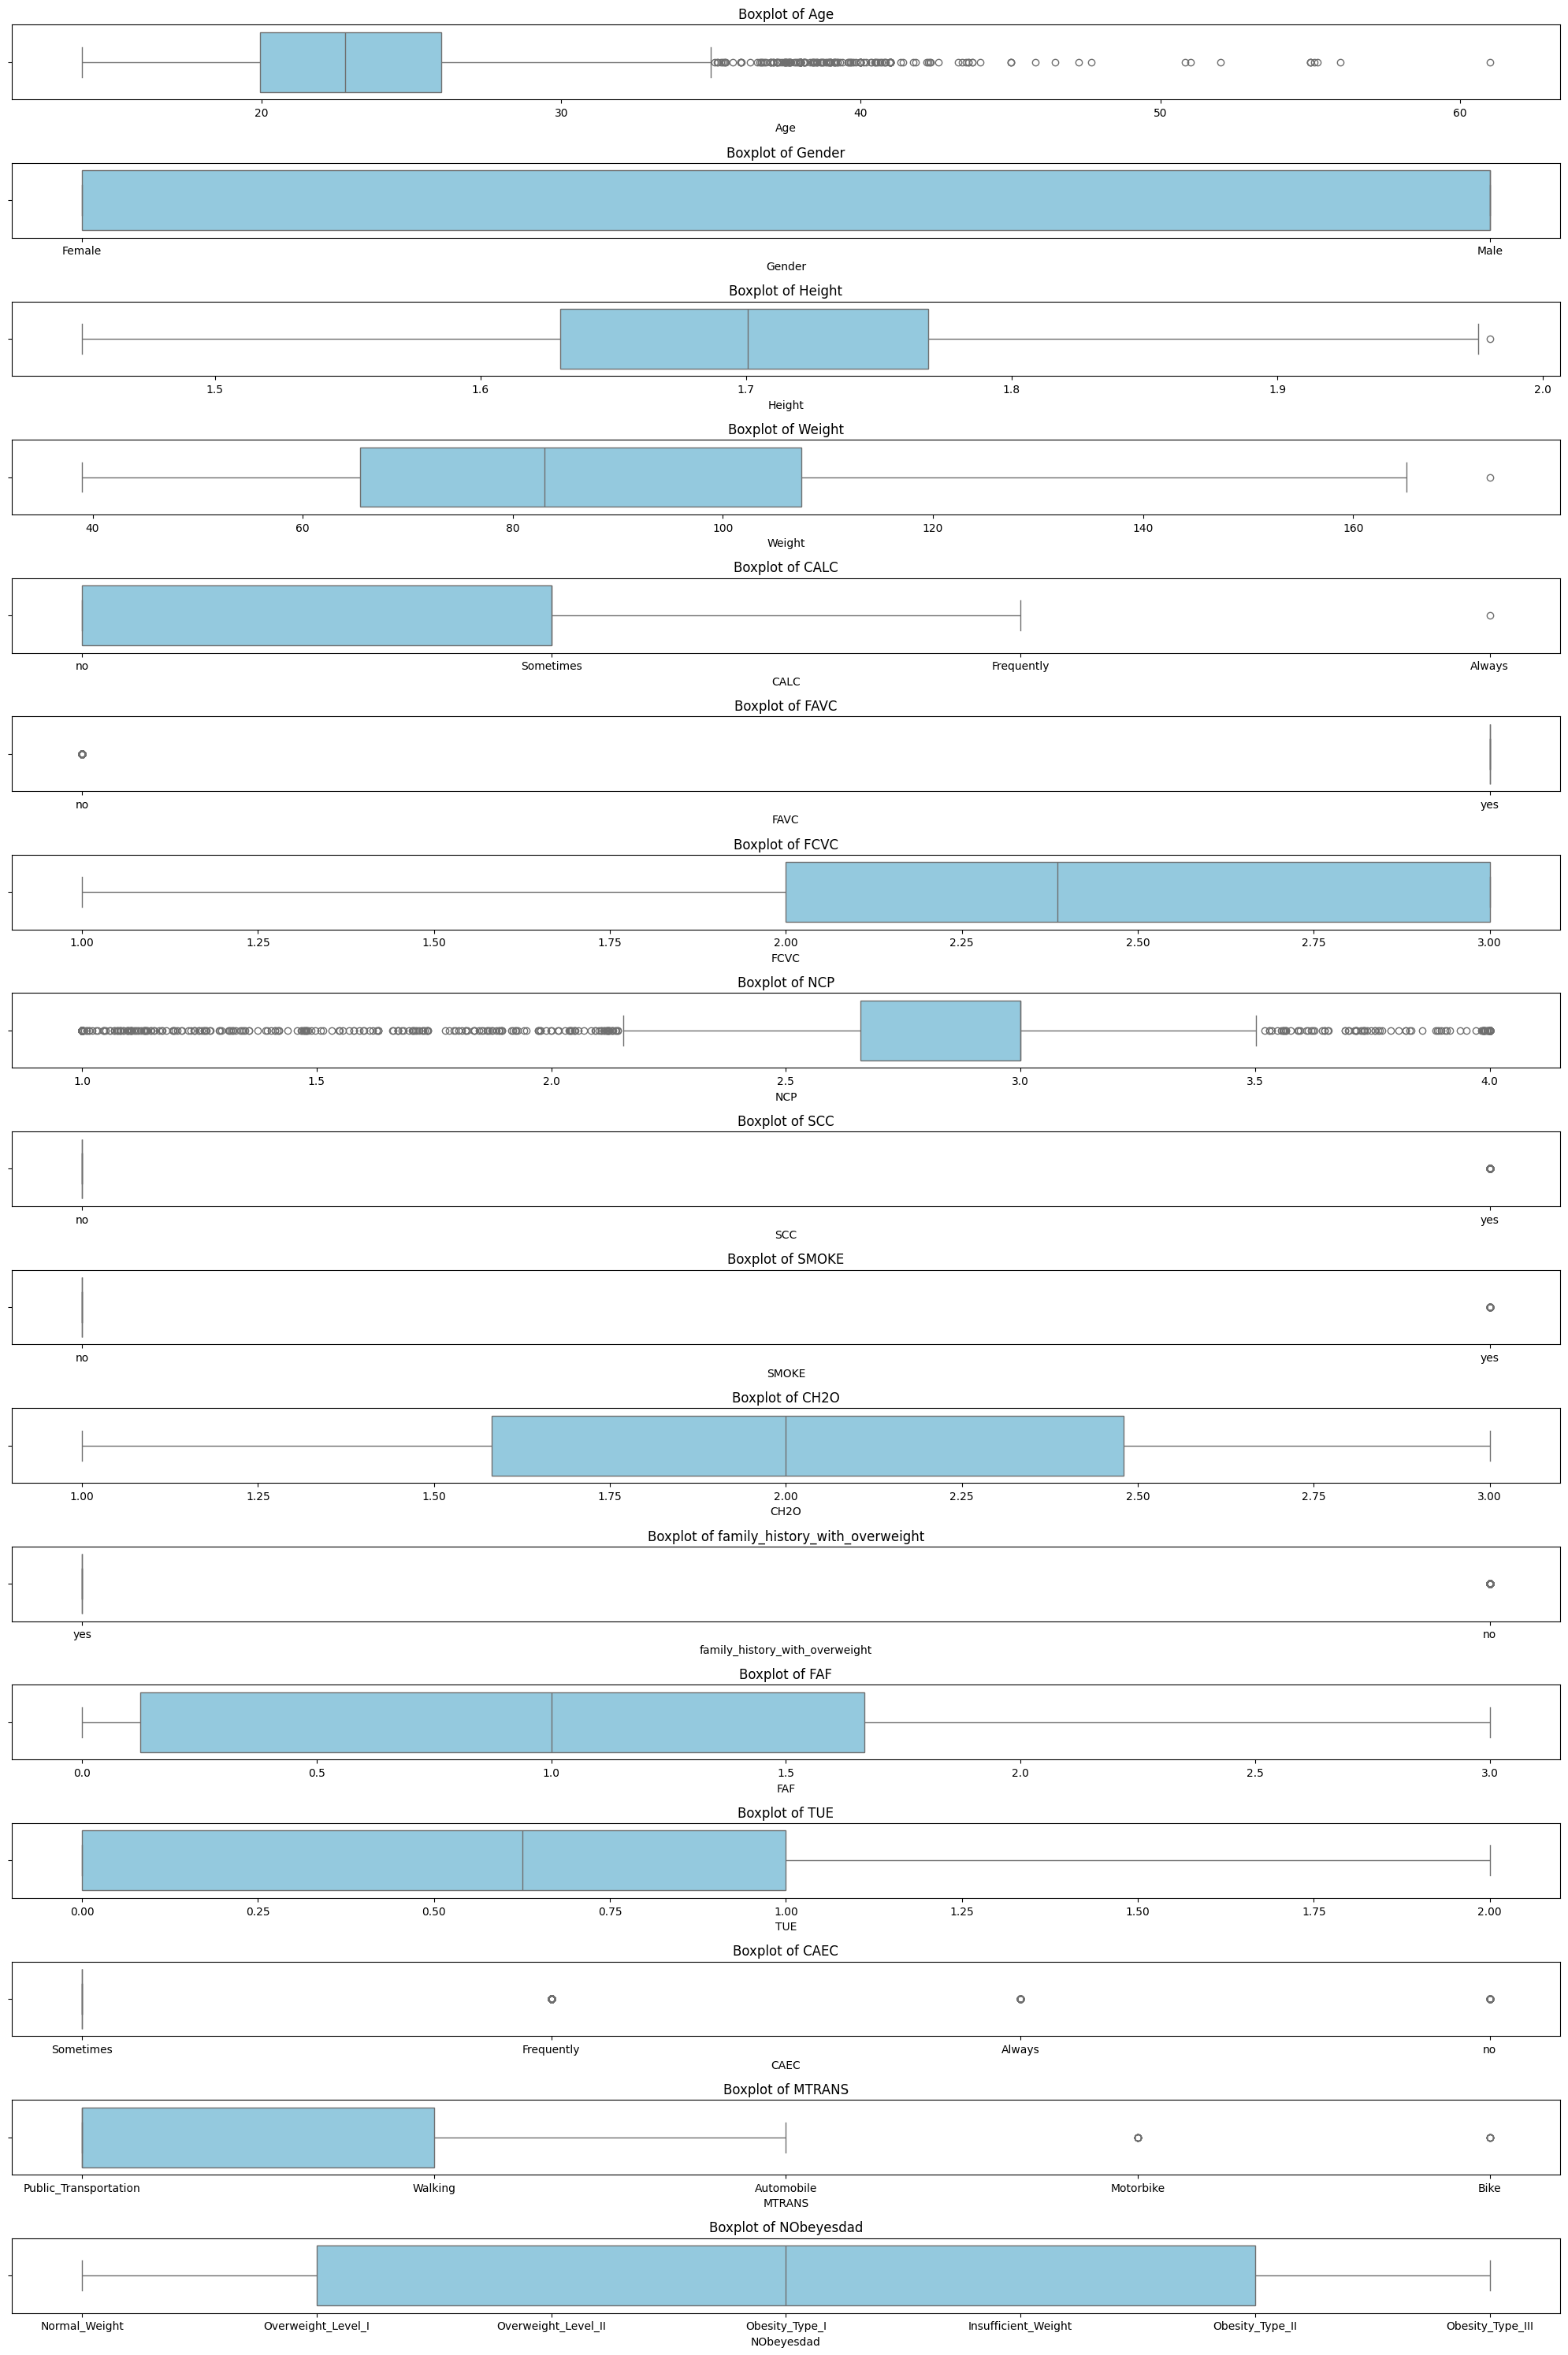

In [83]:
import matplotlib.pyplot as plt
import seaborn as sns

# Select only numerical columns for boxplot analysis
numeric_cols = dataset_encoded.select_dtypes(include=['int64', 'float64']).columns

# Set up the figure
plt.figure(figsize=(20, 30))

# Plot boxplots for each numerical feature including the target variable 'OUTCOME'
for i, col in enumerate(numeric_cols, 1):
    plt.subplot(len(numeric_cols), 1, i)
    sns.boxplot(x=dataset[col], color='skyblue')
    plt.title(f'Boxplot of {col}', fontsize=12)
    plt.tight_layout()

plt.show()

Density plots of features

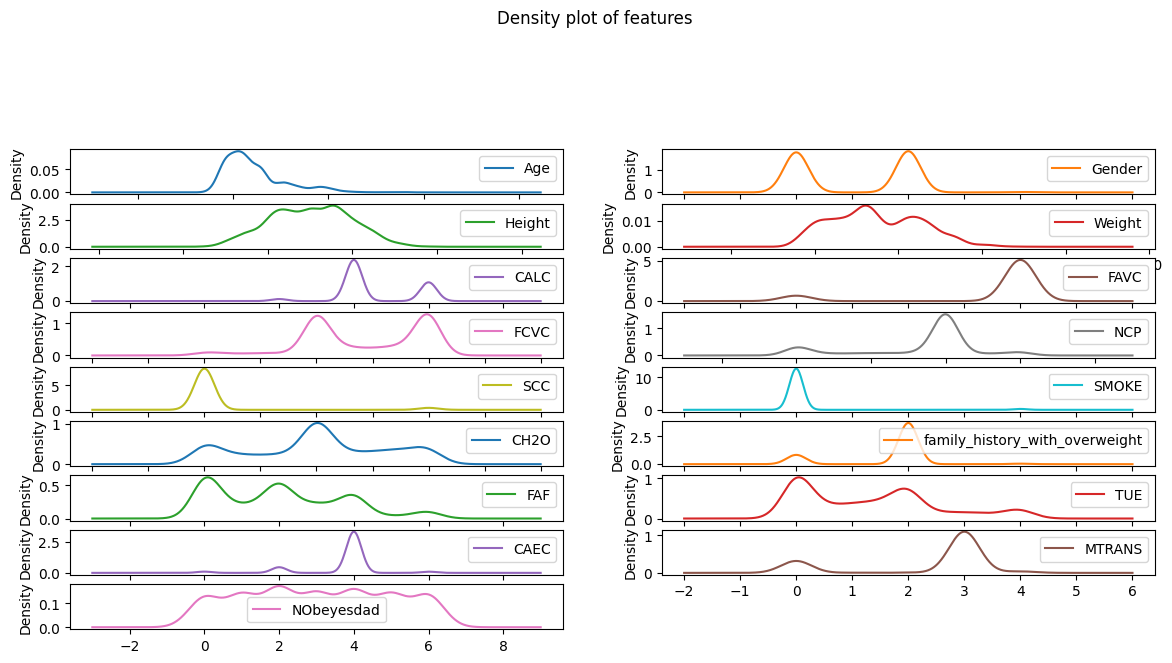

In [84]:
dataset_encoded.plot(kind='density',figsize=(14,14),subplots=True,layout=(20,2),title="Density plot of features",sharex=False)
plt.show()

Data Preprocessing

column dropping

In [85]:
final_dataset=dataset.copy()
final_dataset = final_dataset.drop(['SMOKE','SCC','FAVC','family_history_with_overweight', 'family_history_with_overweight'], axis = 1) #5 columns dropped
final_dataset.shape

(2111, 13)

Null/missing values

In [86]:
final_dataset.isnull().sum()

,0
Age,0
Gender,11
Height,0
Weight,0
CALC,0
FCVC,0
NCP,0
CH2O,21
FAF,0
TUE,0


Dropping rows with null values

In [87]:
# Check how many values are missing in the CH2O column
print("Number of rows with null values in CH2O column: ", final_dataset['CH2O'].isnull().sum())

# Subset the  dataset
data_subset = final_dataset[final_dataset['CH2O'].notnull()]

# Print out the shape of the subset
print("Shape after removing null values: ", data_subset.shape)
print("Shape of dataframe before dropping:", final_dataset.shape)
final_dataset = final_dataset.dropna(axis = 0, subset = ['CH2O'])
print("Shape after dropping:", final_dataset.shape)

Number of rows with null values in CH2O column:  21
Shape after removing null values:  (2090, 13)
Shape of dataframe before dropping: (2111, 13)
Shape after dropping: (2090, 13)


In [88]:
# Check how many values are missing in the Gender column
print("Number of rows with null values in Gender column: ", final_dataset['Gender'].isnull().sum())

# Subset the  dataset
data_subset = final_dataset[final_dataset['Gender'].notnull()]

# Print out the shape of the subset
print("Shape after removing null values: ", data_subset.shape)
print("Shape of dataframe before dropping:", final_dataset.shape)
final_dataset = final_dataset.dropna(axis = 0, subset = ['Gender'])
print("Shape after dropping:", final_dataset.shape)

Number of rows with null values in Gender column:  11
Shape after removing null values:  (2079, 13)
Shape of dataframe before dropping: (2090, 13)
Shape after dropping: (2079, 13)


Encoding

In [89]:
arr=['CALC', 'CAEC', 'MTRANS', 'NObeyesdad']
for i in arr:
    print(i,final_dataset[i].unique())

CALC ['no' 'Sometimes' 'Frequently' 'Always']
CAEC ['Sometimes' 'Frequently' 'Always' 'no']
MTRANS ['Public_Transportation' 'Walking' 'Automobile' 'Motorbike' 'Bike']
NObeyesdad ['Normal_Weight' 'Overweight_Level_I' 'Overweight_Level_II'
 'Obesity_Type_I' 'Insufficient_Weight' 'Obesity_Type_II'
 'Obesity_Type_III']


In [90]:
from sklearn.preprocessing import LabelEncoder
dataset_encoded = dataset.copy()
encoder = LabelEncoder()

for col in ['Gender']:
    final_dataset[col] = encoder.fit_transform(final_dataset[col])
print(final_dataset[[ 'Gender']].head())


   Gender
0       0
1       0
2       1
3       1
4       1


In [91]:


from sklearn.preprocessing import OneHotEncoder


categorical_columns =  ['CALC', 'CAEC', 'MTRANS', 'NObeyesdad']
encoder = OneHotEncoder(sparse_output=False)

one_hot_encoded = encoder.fit_transform(final_dataset[categorical_columns])

one_hot_df = pd.DataFrame(one_hot_encoded, columns=encoder.get_feature_names_out(categorical_columns))

processed_dataset = pd.concat([final_dataset, one_hot_df], axis=1)

processed_dataset= processed_dataset.drop(categorical_columns, axis=1)
print(f"Encoded Employee data : \n{processed_dataset}")

Encoded Employee data : 
       Age  Gender  Height  Weight  FCVC  NCP  CH2O  FAF  TUE  CALC_Always  \
0     21.0     0.0    1.62    64.0   2.0  3.0   2.0  0.0  1.0          0.0   
1     21.0     0.0    1.52    56.0   3.0  3.0   3.0  3.0  0.0          0.0   
2     23.0     1.0    1.80    77.0   2.0  3.0   2.0  2.0  1.0          0.0   
3     27.0     1.0    1.80    87.0   3.0  3.0   2.0  2.0  0.0          0.0   
4     22.0     1.0    1.78    89.8   2.0  1.0   2.0  0.0  0.0          0.0   
...    ...     ...     ...     ...   ...  ...   ...  ...  ...          ...   
1561   NaN     NaN     NaN     NaN   NaN  NaN   NaN  NaN  NaN          0.0   
1656   NaN     NaN     NaN     NaN   NaN  NaN   NaN  NaN  NaN          0.0   
1812   NaN     NaN     NaN     NaN   NaN  NaN   NaN  NaN  NaN          0.0   
1916   NaN     NaN     NaN     NaN   NaN  NaN   NaN  NaN  NaN          0.0   
2057   NaN     NaN     NaN     NaN   NaN  NaN   NaN  NaN  NaN          0.0   

      ...  MTRANS_Motorbike  MTRANS_Pu

In [92]:
# Check how many values are missing in the CALC_Always column
print("Number of rows with null values in CALC_Always column: ", processed_dataset['CALC_Always'].isnull().sum())

# Subset the  dataset
data_subset = processed_dataset[processed_dataset['CALC_Always'].notnull()]

# Print out the shape of the subset
print("Shape after removing null values: ", data_subset.shape)
print("Shape of dataframe before dropping:", processed_dataset.shape)
processed_dataset = processed_dataset.dropna(axis = 0, subset = ['CALC_Always'])
print("Shape after dropping:", processed_dataset.shape)

# Check how many values are missing in the Age column
print("Number of rows with null values in Age column: ", processed_dataset['Age'].isnull().sum())

# Subset the  dataset
data_subset = processed_dataset[processed_dataset['Age'].notnull()]

# Print out the shape of the subset
print("Shape after removing null values: ", data_subset.shape)
print("Shape of dataframe before dropping:", processed_dataset.shape)
processed_dataset = processed_dataset.dropna(axis = 0, subset = ['Age'])
print("Shape after dropping:", processed_dataset.shape)

Number of rows with null values in CALC_Always column:  32
Shape after removing null values:  (2079, 29)
Shape of dataframe before dropping: (2111, 29)
Shape after dropping: (2079, 29)
Number of rows with null values in Age column:  32
Shape after removing null values:  (2047, 29)
Shape of dataframe before dropping: (2079, 29)
Shape after dropping: (2047, 29)


In [93]:
processed_dataset.isnull().sum()

,0
Age,0
Gender,0
Height,0
Weight,0
FCVC,0
NCP,0
CH2O,0
FAF,0
TUE,0
CALC_Always,0


In [94]:
processed_dataset.head()

,Age,Gender,Height,Weight,FCVC,NCP,CH2O,FAF,TUE,CALC_Always,...,MTRANS_Motorbike,MTRANS_Public_Transportation,MTRANS_Walking,NObeyesdad_Insufficient_Weight,NObeyesdad_Normal_Weight,NObeyesdad_Obesity_Type_I,NObeyesdad_Obesity_Type_II,NObeyesdad_Obesity_Type_III,NObeyesdad_Overweight_Level_I,NObeyesdad_Overweight_Level_II
0,21.0,0.0,1.62,64.0,2.0,3.0,2.0,0.0,1.0,0.0,...,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
1,21.0,0.0,1.52,56.0,3.0,3.0,3.0,3.0,0.0,0.0,...,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
2,23.0,1.0,1.80,77.0,2.0,3.0,2.0,2.0,1.0,0.0,...,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
3,27.0,1.0,1.80,87.0,3.0,3.0,2.0,2.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
4,22.0,1.0,1.78,89.8,2.0,1.0,2.0,0.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0


Scaling

In [95]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler
standard_features = ['Height', 'Weight']
minmax_features = ['FCVC', 'NCP', 'CH2O', 'FAF', 'TUE']

# Create scaler objects
standard_scaler = StandardScaler()
minmax_scaler = MinMaxScaler()

# Apply StandardScaler
processed_dataset[standard_features] = standard_scaler.fit_transform(processed_dataset[standard_features])

# Apply MinMaxScaler
processed_dataset[minmax_features] = minmax_scaler.fit_transform(processed_dataset[minmax_features])

# Show scaled data
print(processed_dataset.head())

    Age  Gender    Height    Weight  FCVC       NCP  CH2O       FAF  TUE  \
0  21.0     0.0 -0.878056 -0.852983   0.5  0.666667   0.5  0.000000  0.5   
1  21.0     0.0 -1.944030 -1.159938   1.0  0.666667   1.0  1.000000  0.0   
2  23.0     1.0  1.040697 -0.354181   0.5  0.666667   0.5  0.666667  0.5   
3  27.0     1.0  1.040697  0.029513   1.0  0.666667   0.5  0.666667  0.0   
4  22.0     1.0  0.827502  0.136947   0.5  0.000000   0.5  0.000000  0.0   

   CALC_Always  ...  MTRANS_Motorbike  MTRANS_Public_Transportation  \
0          0.0  ...               0.0                           1.0   
1          0.0  ...               0.0                           1.0   
2          0.0  ...               0.0                           1.0   
3          0.0  ...               0.0                           0.0   
4          0.0  ...               0.0                           1.0   

   MTRANS_Walking  NObeyesdad_Insufficient_Weight  NObeyesdad_Normal_Weight  \
0             0.0                    

Dataset splitting

In [96]:
from sklearn.model_selection import train_test_split


# Separate features  and target
data = processed_dataset.drop('Age', axis=1)   # all features
target = processed_dataset['Age']                # target variable

# Random split 70-30
X_train, X_test, y_train, y_test = train_test_split(data, target, test_size = 0.3, random_state=000, shuffle=True   )
print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)
print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)

X_train shape: (1432, 28)
y_train shape: (1432,)
X_test shape: (615, 28)
y_test shape: (615,)


Model Training and testing

In [97]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.cluster import KMeans
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

In [98]:
# 1. Linear Regression

lin_reg = LinearRegression()
lin_reg.fit(X_train, y_train)
y_pred_lr = lin_reg.predict(X_test)

print("The Training accuracy of the model is {:.2f}".format(lin_reg.score(X_train, y_train)))
print("The Testing accuracy of the model is {:.2f}".format(lin_reg.score(X_test, y_test)))

The Training accuracy of the model is 0.25
The Testing accuracy of the model is 0.15


In [99]:
# 2. Decision Tree

dt_reg = DecisionTreeRegressor(random_state=000, max_depth=10)
dt_reg.fit(X_train, y_train)
y_pred_dt = dt_reg.predict(X_test)

print("The Training accuracy of the model is {:.2f}".format(dt_reg.score(X_train, y_train)))
print("The Testing accuracy of the model is {:.2f}".format(dt_reg.score(X_test, y_test)))

The Training accuracy of the model is 0.89
The Testing accuracy of the model is 0.03


In [100]:
# 3. Neural Network (MLP)

nn_reg = MLPRegressor(hidden_layer_sizes=(128,64), max_iter=1000, random_state=000)
nn_reg.fit(X_train, y_train)
y_pred_nn = nn_reg.predict(X_test)

print("The Training accuracy of the model is {:.2f}".format(nn_reg.score(X_train, y_train)))
print("The Testing accuracy of the model is {:.2f}".format(nn_reg.score(X_test, y_test)))

The Training accuracy of the model is 0.71
The Testing accuracy of the model is 0.27


     Age  Group_cluster
0   21.0              0
1   21.0              0
2   23.0              0
3   27.0              2
4   22.0              0
5   29.0              2
6   23.0              0
7   22.0              0
8   24.0              2
9   22.0              0
10  26.0              2
11  21.0              0
12  22.0              0
13  41.0              1
14  23.0              0


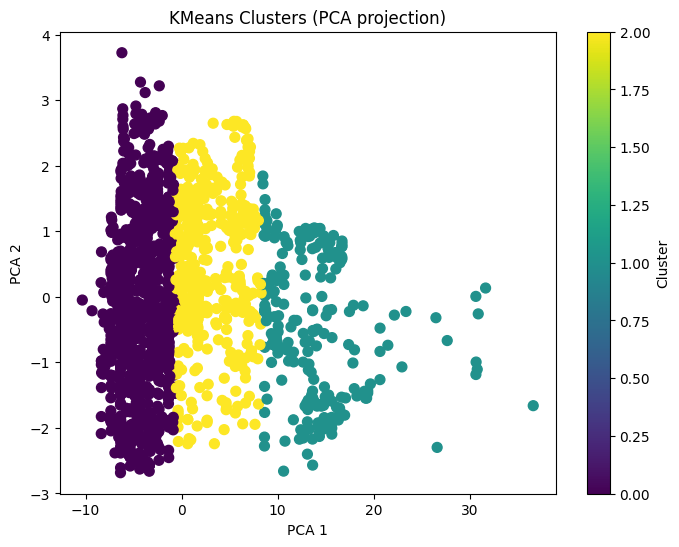

In [106]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

# Function to implement KMeans
def implement_KMC(df_temp, cluster_num):
    km = KMeans(n_clusters=cluster_num, random_state=42)  # reproducibility
    y_predicted = km.fit_predict(df_temp)
    return km, y_predicted

# Select features for clustering (scaled ones + Age)
features_for_clustering = ['Age','Height','Weight','FCVC','NCP','CH2O','FAF','TUE']
X = processed_dataset[features_for_clustering]

# Run KMeans
cluster = 3
km, y_predicted = implement_KMC(X, cluster)

# Add cluster labels to dataset
processed_dataset["Group_cluster"] = y_predicted

print(processed_dataset[['Age','Group_cluster']].head(15))

# ---- Visualization ----
# Reduce to 2D using PCA for plotting
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)

plt.figure(figsize=(8,6))
plt.scatter(X_pca[:,0], X_pca[:,1], c=y_predicted, cmap='viridis', s=50)
plt.title("KMeans Clusters (PCA projection)")
plt.xlabel("PCA 1")
plt.ylabel("PCA 2")
plt.colorbar(label="Cluster")
plt.show()


Comparison analysis

In [103]:
# Evaluation Function

def evaluate_model(name, y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)


    r2 = r2_score(y_true, y_pred)
    return {
        'Model': name,

        'MSE/loss': round(mse,2),
        'R2 Score': round(r2,2)
    }

# Collect results
results = []
results.append(evaluate_model("Linear Regression", y_test, y_pred_lr))
results.append(evaluate_model("Decision Tree", y_test, y_pred_dt))
results.append(evaluate_model("Neural Network", y_test, y_pred_nn))

# Convert to DataFrame
results_df = pd.DataFrame(results)
print("\nModel Comparison:")
print(results_df)




Model Comparison:
               Model  MSE/loss  R2 Score
0  Linear Regression     33.55      0.15
1      Decision Tree     38.62      0.03
2     Neural Network     29.04      0.27


Neural Network Epoch-wise training loss curve.

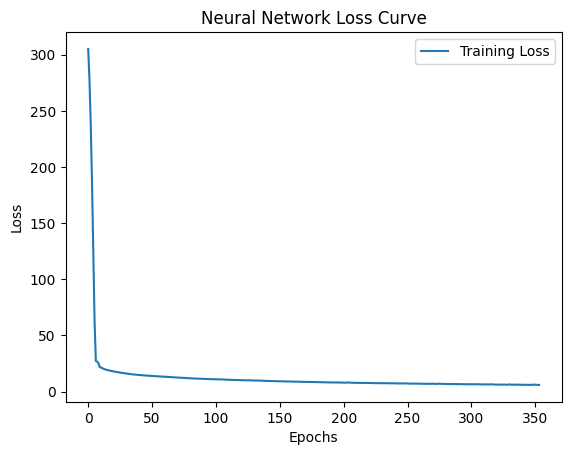

In [104]:
def plot_nn_loss(nn_model):
    plt.plot(nn_model.loss_curve_, label="Training Loss")
    plt.title("Neural Network Loss Curve")
    plt.xlabel("Epochs")
    plt.ylabel("Loss")
    plt.legend()
    plt.show()


plot_nn_loss(nn_reg)

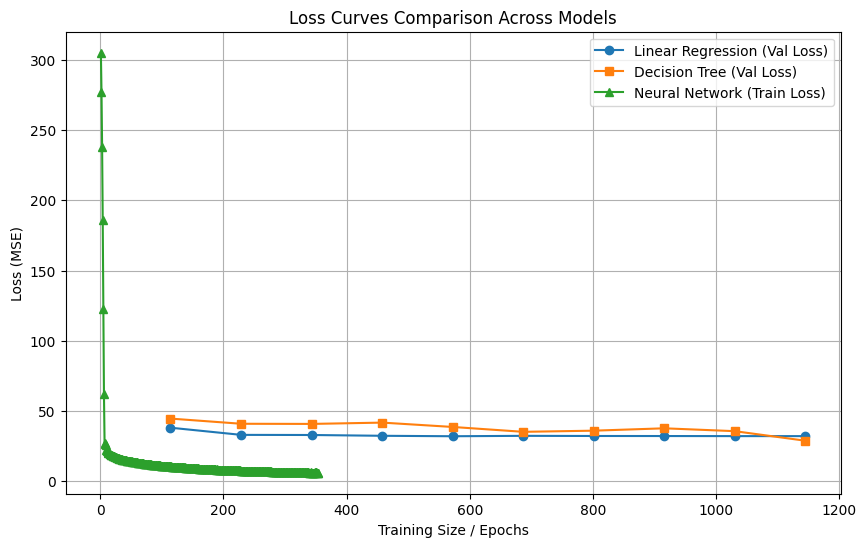

In [105]:
import matplotlib.pyplot as plt
from sklearn.model_selection import learning_curve
import numpy as np

def combined_loss_curves(lr, dt, nn, X_train, y_train):
    plt.figure(figsize=(10,6))

    # Linear Regression Learning Curve

    train_sizes, train_scores, val_scores = learning_curve(
        lr, X_train, y_train, cv=5, scoring='neg_mean_squared_error',
        train_sizes=np.linspace(0.1, 1.0, 10), n_jobs=-1
    )
    lr_val_loss = -np.mean(val_scores, axis=1)
    plt.plot(train_sizes, lr_val_loss, 'o-', label="Linear Regression (Val Loss)")

    # Decision Tree Learning Curve

    train_sizes, train_scores, val_scores = learning_curve(
        dt, X_train, y_train, cv=5, scoring='neg_mean_squared_error',
        train_sizes=np.linspace(0.1, 1.0, 10), n_jobs=-1
    )
    dt_val_loss = -np.mean(val_scores, axis=1)
    plt.plot(train_sizes, dt_val_loss, 's-', label="Decision Tree (Val Loss)")


    # Neural Network Loss Curve

    plt.plot(range(1, len(nn.loss_curve_)+1), nn.loss_curve_, '^-', label="Neural Network (Train Loss)")


    # Formatting

    plt.title("Loss Curves Comparison Across Models")
    plt.xlabel("Training Size / Epochs")
    plt.ylabel("Loss (MSE)")
    plt.legend()
    plt.grid(True)
    plt.show()
combined_loss_curves(lin_reg, dt_reg, nn_reg, X_train, y_train)
